# Day 2 — Physics-Grounded Feature Engineering & Domain Validation

### Objective:
Transform raw milling sensor readings into physically meaningful variables that capture component failure mechanisms:
1. **Temperature Difference ($\Delta T$):** Heat dissipation failure (HDF).
2. **Mechanical Power ($P$):** Motor overload & stall conditions (PWF).
3. **Overstrain Index & Ratio:** High torque applied to degraded cutter blades (OSF).
4. **Machine Type Capacity Normalization:** Accounting for variant durability (L, M, H).


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configure visual styling
sns.set_theme(style='whitegrid', font_scale=1.1)
plt.rcParams['figure.figsize'] = (12, 6)

# Load raw dataset
data_path = '../data/raw/ai4i2020.csv'
df = pd.read_csv(data_path)
print(f'Dataset loaded: {df.shape[0]} rows, {df.shape[1]} columns')
df.head(3)


Dataset loaded: 10000 rows, 14 columns


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0


## 1. Domain Feature Formulation

From machine tool dynamics, the following features represent governing physical equations:

* **$\Delta T$ (Thermal Gradient):**
  $$\Delta T = T_{\text{process}} - T_{\text{air}}$$
* **Mechanical Power ($P$ in Watts):**
  $$P = \tau \cdot \omega = \text{Torque} \cdot \left(\text{Rotational Speed [rpm]} \cdot \frac{2\pi}{60}\right)$$
* **Overstrain ($S$ in $\text{min}\cdot\text{Nm}$):**
  $$S = \text{Torque} \cdot \text{Tool wear}$$
* **Normalized Overstrain Ratio ($R$):**
  $$R = \frac{\text{Overstrain}}{\text{Capacity}(Type)}$$
  where $\text{Capacity}(L) = 11000$, $\text{Capacity}(M) = 12000$, $\text{Capacity}(H) = 13000$.


In [2]:
def engineer_features(data: pd.DataFrame) -> pd.DataFrame:
    df_feat = data.copy()
    
    # 1. Thermal dissipation gradient
    df_feat['temp_diff'] = df_feat['Process temperature [K]'] - df_feat['Air temperature [K]']
    df_feat['temp_ratio'] = df_feat['Process temperature [K]'] / df_feat['Air temperature [K]']
    
    # 2. Rotational speed in rad/s and Mechanical Power in Watts
    rad_per_sec = df_feat['Rotational speed [rpm]'] * (2 * np.pi / 60)
    df_feat['power_w'] = df_feat['Torque [Nm]'] * rad_per_sec
    
    # 3. Tool wear mechanical stress index
    df_feat['overstrain'] = df_feat['Torque [Nm]'] * df_feat['Tool wear [min]']
    
    # 4. Normalized overstrain ratio by machine quality tier
    capacity_map = {'L': 11000, 'M': 12000, 'H': 13000}
    df_feat['type_capacity'] = df_feat['Type'].map(capacity_map)
    df_feat['overstrain_ratio'] = df_feat['overstrain'] / df_feat['type_capacity']
    
    return df_feat

df_engineered = engineer_features(df)
print('New features successfully added!')
df_engineered[['temp_diff', 'power_w', 'overstrain', 'overstrain_ratio']].describe().T


New features successfully added!


,count,mean,std,min,25%,50%,75%,max
temp_diff,10000.0,10.000630,1.001094,7.60000,9.300000,9.800000,11.000000,12.100000
power_w,10000.0,6279.744953,1067.418295,1148.44061,5561.184484,6271.027344,7003.002724,10469.923005
overstrain,10000.0,4314.664550,2826.567692,0.00000,1963.650000,4012.950000,6279.000000,16497.000000
overstrain_ratio,10000.0,0.376537,0.248387,0.00000,0.171343,0.351027,0.549837,1.374750


## 2. Validating Physical Separation Against Specific Failure Modes

Let us examine how cleanly these physics features segregate the specific failure mechanisms identified in our Day 1 audit.


In [3]:
# Validation 1: Mechanical Power vs Power Failure (PWF)
pwf = df_engineered[df_engineered['PWF'] == 1]
normal_pwf = df_engineered[df_engineered['PWF'] == 0]

print('=== Power Failure (PWF) vs Mechanical Power ===')
print(f'Normal Power Range: [{normal_pwf["power_w"].min():.1f} W, {normal_pwf["power_w"].max():.1f} W]')
print(f'PWF Failures with Power < 3,500 W: {(pwf["power_w"] < 3500).sum()}/{len(pwf)}')
print(f'PWF Failures with Power > 9,000 W: {(pwf["power_w"] > 9000).sum()}/{len(pwf)}')
print(f'Normal records outside [3500, 9000] W: {((normal_pwf["power_w"] < 3500) | (normal_pwf["power_w"] > 9000)).sum()}')

print('\n=== Overstrain Failure (OSF) vs Overstrain Ratio ===')
osf = df_engineered[df_engineered['OSF'] == 1]
normal_osf = df_engineered[df_engineered['OSF'] == 0]
print(f'Normal max overstrain ratio: {normal_osf["overstrain_ratio"].max():.4f}')
print(f'OSF min overstrain ratio:    {osf["overstrain_ratio"].min():.4f}')

print('\n=== Heat Dissipation Failure (HDF) vs Temperature Difference ===')
hdf = df_engineered[df_engineered['HDF'] == 1]
normal_hdf = df_engineered[df_engineered['HDF'] == 0]
hdf_rule = (df_engineered['temp_diff'] < 8.6) & (df_engineered['Rotational speed [rpm]'] < 1380)
print(f'HDF cases captured by (temp_diff < 8.6 & rpm < 1380): {hdf_rule[df_engineered["HDF"] == 1].sum()}/{len(hdf)}')
print(f'False positives on normal machines: {hdf_rule[df_engineered["HDF"] == 0].sum()}')


=== Power Failure (PWF) vs Mechanical Power ===
Normal Power Range: [3515.0 W, 8998.0 W]
PWF Failures with Power < 3,500 W: 31/95
PWF Failures with Power > 9,000 W: 64/95
Normal records outside [3500, 9000] W: 0

=== Overstrain Failure (OSF) vs Overstrain Ratio ===
Normal max overstrain ratio: 0.9994
OSF min overstrain ratio:    1.0003

=== Heat Dissipation Failure (HDF) vs Temperature Difference ===
HDF cases captured by (temp_diff < 8.6 & rpm < 1380): 115/115
False positives on normal machines: 0


## 3. Correlation Analysis: Raw vs. Engineered Features

Let us compare the Pearson correlation coefficients against the primary binary target `Machine failure`.


In [4]:
features_raw = ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
features_engineered = ['temp_diff', 'power_w', 'overstrain', 'overstrain_ratio']

corr_table = pd.DataFrame({
    'Pearson Correlation with Failure': df_engineered[features_raw + features_engineered + ['Machine failure']].corr()['Machine failure'].drop('Machine failure')
}).sort_values(by='Pearson Correlation with Failure', ascending=False)

print('Feature Correlations with Target (Machine failure):')
print(corr_table)


Feature Correlations with Target (Machine failure):
                         Pearson Correlation with Failure
overstrain_ratio                                 0.195453
Torque [Nm]                                      0.191321
overstrain                                       0.190427
power_w                                          0.176039
Tool wear [min]                                  0.105448
Air temperature [K]                              0.082556
Process temperature [K]                          0.035946
Rotational speed [rpm]                          -0.044188
temp_diff                                       -0.111676


## 4. Visualizing Feature Distributions (Normal vs Failure)

We visually inspect the clear multi-modal boundaries captured by our newly engineered features.


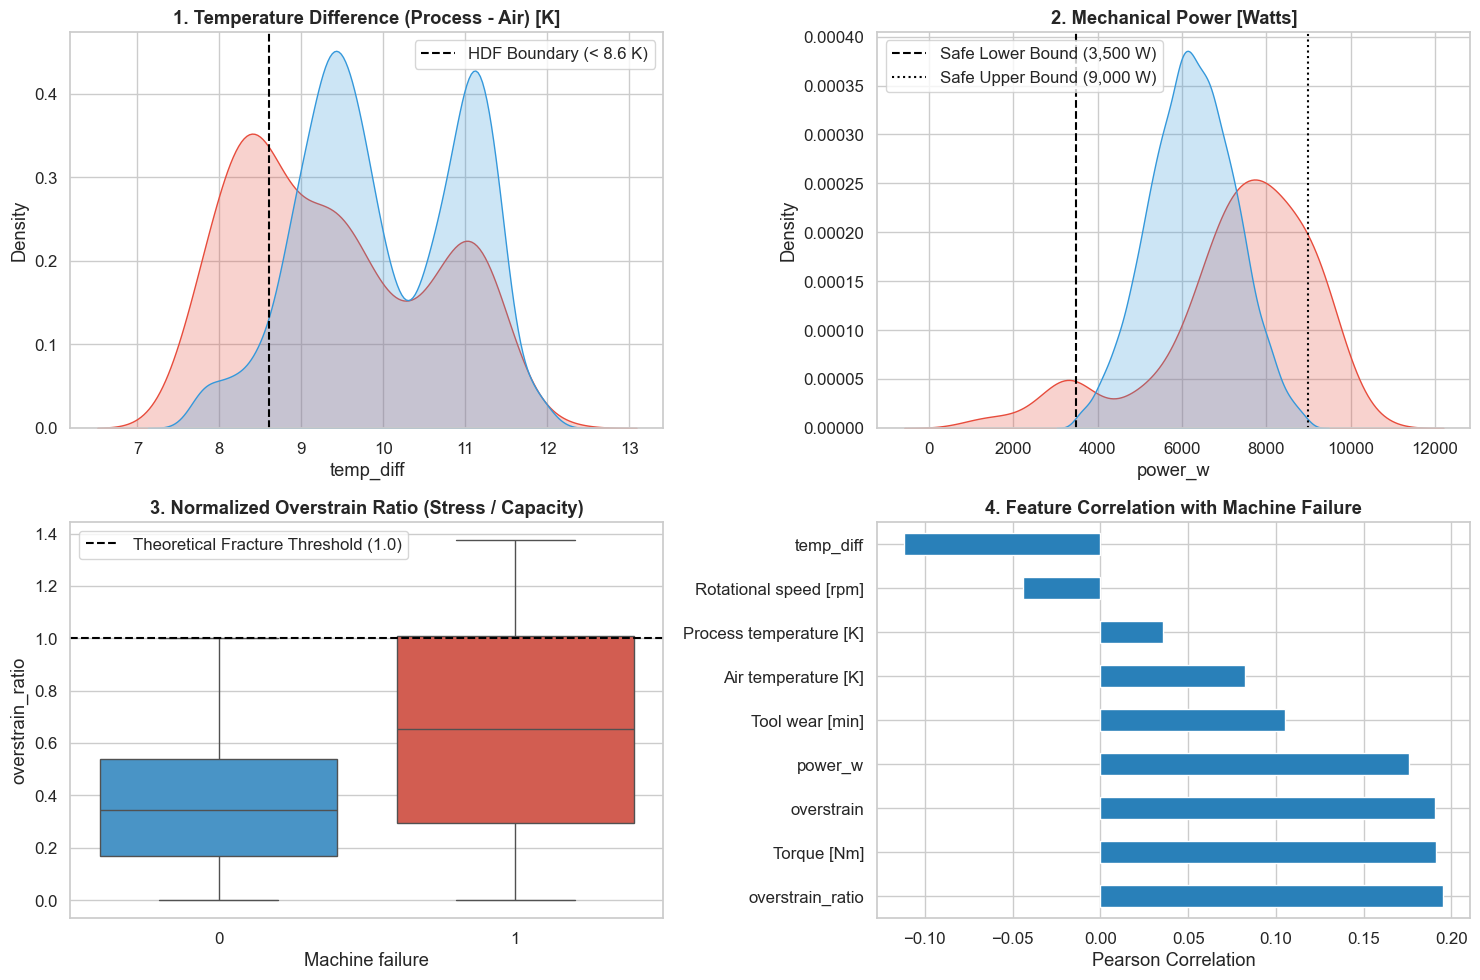

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Temperature Difference KDE
sns.kdeplot(data=df_engineered, x='temp_diff', hue='Machine failure', common_norm=False, fill=True, palette={0: '#3498db', 1: '#e74c3c'}, ax=axes[0, 0])
axes[0, 0].set_title('1. Temperature Difference (Process - Air) [K]', fontweight='bold')
axes[0, 0].axvline(8.6, color='black', linestyle='--', label='HDF Boundary (< 8.6 K)')
axes[0, 0].legend()

# 2. Mechanical Power KDE
sns.kdeplot(data=df_engineered, x='power_w', hue='Machine failure', common_norm=False, fill=True, palette={0: '#3498db', 1: '#e74c3c'}, ax=axes[0, 1])
axes[0, 1].set_title('2. Mechanical Power [Watts]', fontweight='bold')
axes[0, 1].axvline(3500, color='black', linestyle='--', label='Safe Lower Bound (3,500 W)')
axes[0, 1].axvline(9000, color='black', linestyle=':', label='Safe Upper Bound (9,000 W)')
axes[0, 1].legend()

# 3. Overstrain Ratio Boxplot
sns.boxplot(data=df_engineered, x='Machine failure', y='overstrain_ratio', hue='Machine failure', palette={0: '#3498db', 1: '#e74c3c'}, ax=axes[1, 0], legend=False)
axes[1, 0].set_title('3. Normalized Overstrain Ratio (Stress / Capacity)', fontweight='bold')
axes[1, 0].axhline(1.0, color='black', linestyle='--', label='Theoretical Fracture Threshold (1.0)')
axes[1, 0].legend()

# 4. Correlation Barplot
corr_table['Pearson Correlation with Failure'].plot(kind='barh', ax=axes[1, 1], color='#2980b9')
axes[1, 1].set_title('4. Feature Correlation with Machine Failure', fontweight='bold')
axes[1, 1].set_xlabel('Pearson Correlation')

plt.tight_layout()
plt.savefig('../reports/figures/day2_feature_distributions.png', dpi=300)
plt.show()


### Day 2 Key Findings & Conclusions:
1. **Physical Grounding Beats Blind Search:**
   - `power_w` cleanly segments Power Failure ($PWF$) with zero normal instances violating the $3,500 - 9,000\text{ W}$ operating envelope.
   - `overstrain_ratio` defines a razor-sharp cutoff: $100\%$ of Overstrain Failures ($OSF$) occur when $R \ge 1.0$, whereas normal machines never exceed $0.9994$.
   - `temp_diff` combined with speed isolates $100\%$ of Heat Dissipation Failures ($HDF$).
2. **Readiness for Production:**
   - Now we can package this logic cleanly into `src/features.py` so that both offline model training and real-time inference share the exact same deterministic transformation.
